In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from rm_noise import camb_spectra, white_instrument, Geometry, reconstruction_noise

In [2]:
PRISM = np.array(
    [
        [30, 17, 13],
        [36, 14, 8.5],
        [43, 12, 8],
        [51, 10, 6.2],
        [62, 8.2, 6],
        [75, 6.8, 5.6],
        [90, 5.7, 5.4],
    ]
)
REFERENCE = np.array([[30, 1, 1]])

In [3]:
LMAX_CMB, LMAX_RM = 2000, 100
prim, lensed = camb_spectra(LMAX_CMB)
geo = Geometry(LMAX_CMB, LMAX_RM)

In [4]:
L = np.arange(1, LMAX_RM+1)
curves = {}
experiments = [
    ("single", PRISM[1:2], "#292929", [0]),
    ("prism", PRISM, "#215cb1", [0, 0.14, 1]),
    ("reference", REFERENCE, "#11804a", [0, 0.14, 1]),
]
for name, bands, color, residuals in experiments:
    for residual in residuals:
        instrument = white_instrument(bands, LMAX_CMB)
        noise = reconstruction_noise(geo, prim, lensed, instrument, residual)[1:]
        curves[f"{name}_{residual}"] = L*(L+1)*noise/(2*np.pi)

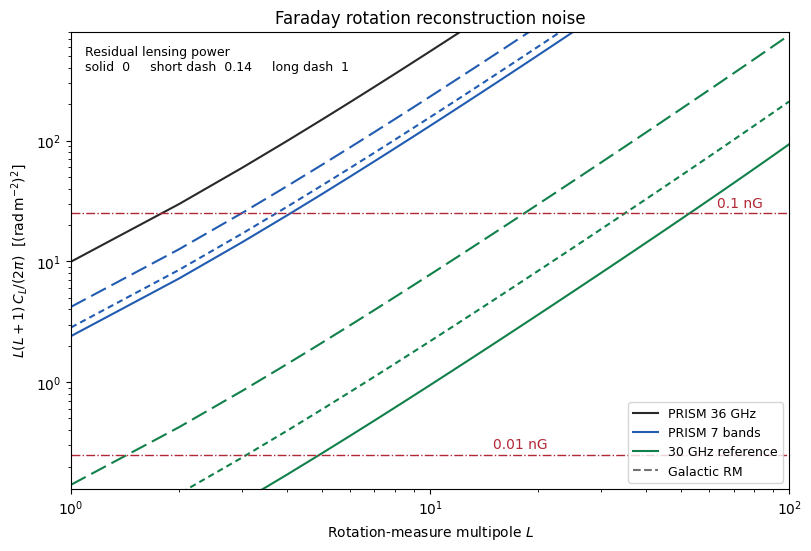

In [5]:
fig, ax = plt.subplots(figsize=(8, 5.4), layout="constrained")
styles = {0: "-", 0.14: (0, (3, 2)), 1: (0, (8, 3))}
for name, bands, color, residuals in experiments:
    for residual in residuals:
        ax.loglog(L, curves[f"{name}_{residual}"], color=color, ls=styles[residual])

for field in [0.1, 0.01]:
    B = str(field)
    level = (50 * field)**2
    ax.axhline(level, color="#b12837", ls="-.", lw=1)
    ax.text(15 if B == "0.01" else 63, level * 1.13, f"{B} nG", color="#b12837")

handles = [
    Line2D([], [], color=c, label=s)
    for c, s in [
        ("#292929", "PRISM 36 GHz"),
        ("#215cb1", "PRISM 7 bands"),
        ("#11804a", "30 GHz reference"),
    ]
]
handles.append(Line2D([], [], color="0.45", ls="--", label="Galactic RM"))
ax.legend(handles=handles, loc="lower right", fontsize=9)
ax.set(
    xlim=(1, 100),
    ylim=(0.13, 800),
    xlabel="Rotation-measure multipole $L$",
    ylabel=r"$L(L+1)\,C_L/(2\pi)$  $[(\mathrm{rad}\,\mathrm{m}^{-2})^2]$",
    title="Faraday rotation reconstruction noise",
)
ax.text(
    0.02,
    0.97,
    "Residual lensing power\nsolid  0     short dash  0.14     long dash  1",
    transform=ax.transAxes,
    va="top",
    fontsize=9,
    bbox=dict(color="white", alpha=0.85),
)

plt.show()